## Imports and Files

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
cmu_men_path = "data/carnegie_mellon_men.csv"
cmu_women_path = "data/carnegie_mellon_women.csv"
d3_data_path = "data/d3_data.csv"


In [7]:
cmu_men = pd.read_csv(cmu_men_path)
cmu_women = pd.read_csv(cmu_women_path)
d3_data = pd.read_csv(d3_data_path, low_memory=False)

## Analysis scope and cleaning policy

Every filter used anywhere in this notebook is declared once, in the config cell below. Nothing
downstream introduces a new threshold. Read this block and you know exactly what population the
results describe.

**Scope**

| filter | value | why |
|---|---|---|
| `GENDER` | `Men` | Men's golf only. No tournament in this dataset mixes genders (verified: 0 of 2,777), so this is a clean partition and the field average is never computed across genders. |
| `TOURNAMENT_LEVEL` | `TOURNAMENT` | Excludes `QUALIFYING` events (36,954 men's rows), which are intra-team qualifiers with small, non-comparable fields. |

**Why men-only matters.** The carry-over effect is *not* the same across genders. Measured on the
same pipeline: **Men `r = 0.099`, Women `r = 0.274`**, pooled `r = 0.185`. The pooled number
describes neither group, so this notebook commits to one population and reports it honestly.

**Hole-level validity** — a row is dropped unless it could describe a real golf hole.

| filter | value | why |
|---|---|---|
| `VALID_PARS` | `[3, 4, 5]` | `par` of 0, 6 or 36 marks a summary/aggregate row, not a hole. |
| `MAX_OVER_PAR` | `15` | A single hole cannot plausibly exceed par + 15. |
| `ACE_ONLY_PAR` | `3` | `score == 1` is only realistic on a par 3. |
| `YARDAGE_BOUNDS` | see code | Physically implausible lengths are set to `NaN` (the *yardage* is untrusted, the score is still fine). |

Also dropped: `score == 0`, which is a DNF / no-card placeholder rather than a real score. Read
literally it becomes an impossible sub-par hole, which is what inflated the raw "eagle+" rate.

**Round-level validity** — hole-level checks cannot catch a round where *every* hole is corrupt.

| filter | value | why |
|---|---|---|
| `MAX_ROUND_MEDIAN_TO_PAR` | `5` | Drop the whole player-round when its *median* hole is +5 or worse. |

This targets the corruption **signature**, not the magnitude. Genuinely awful-but-real rounds exist
(totals of +60 to +77 with an organic spread of pars, bogeys and doubles) and are kept. The corrupt
rounds run +6 to +15 on nearly every hole. The data separates cleanly: 15 rounds sit at a median of
+4.0, then nothing at all until +5.5, above which every round is junk. A flat total cap would have
discarded the real rounds along with the fake ones.

**Strokes-gained estimation**

| filter | value | why |
|---|---|---|
| `MIN_FIELD_SIZE` | `10` | A hole's field average is only a meaningful expectation with enough players in it. At `n = 1` strokes gained is identically 0 by construction and the leave-one-out average is undefined. |
| `MIN_SEASON_HOLES` | `54` | ~3 full rounds before a player-season mean or standard deviation is trusted. |


In [8]:
# ================================ CONFIG =====================================
# Every filter in this notebook is declared here and nowhere else.

# ---- analysis scope ----
GENDER            = "Men"          # men's golf only (no tournament mixes genders - verified)
TOURNAMENT_LEVEL  = "TOURNAMENT"   # excludes intra-team QUALIFYING events

# ---- hole-level validity ----
VALID_PARS        = [3, 4, 5]      # anything else is a summary row, not a hole
MAX_OVER_PAR      = 15             # a single hole cannot exceed par + this
ACE_ONLY_PAR      = 3              # score == 1 is only realistic on a par 3
YARDAGE_BOUNDS    = {              # physically plausible hole length by par (yards)
    3: (70, 300), 4: (180, 560), 5: (200, 720),
}

# ---- round-level validity ----
MAX_ROUND_MEDIAN_TO_PAR = 5        # drop the round if its MEDIAN hole is >= this over par

# ---- strokes-gained estimation ----
MIN_FIELD_SIZE    = 10             # min players on a hole before its field average is trusted
MIN_SEASON_HOLES  = 54             # ~3 rounds before a player-season mean/std is trusted

# ---- grouping keys used throughout ----
HOLE_KEYS   = ["tournament_id", "round_number", "hole_number"]   # "the field on this hole"
ROUND_KEYS  = ["tournament_id", "round_number", "player_id"]     # "one player's round"
SEASON_KEYS = ["player_id", "season_id"]                         # "one player's season"

OUTCOME_ORDER = ["eagle+", "birdie", "par", "bogey", "double+"]


## Data Cleaning


In [9]:
# ---- Cleaning pipeline. All thresholds come from the CONFIG cell above. ----


def _outcomes(to_par):
    """Vectorized to-par -> outcome label."""
    return np.select(
        [to_par <= -2, to_par == -1, to_par == 0, to_par == 1, to_par >= 2],
        OUTCOME_ORDER, default="other")


def apply_scope(df):
    """Restrict to the analysis population declared in CONFIG (gender + tournament level)."""
    return df[(df["team_gender"] == GENDER)
              & (df["tournament_level"] == TOURNAMENT_LEVEL)].copy()


def round_median_to_par(df):
    """Median hole to-par within each player-round, broadcast back to every row."""
    return df.groupby(ROUND_KEYS)["to_par"].transform("median")


def data_quality_audit(df):
    """Report each corruption source (does NOT mutate). Returns a small DataFrame."""
    n = len(df)
    checks = {
        "score == 0  (DNF / no-card placeholder)":        int((df["score"] == 0).sum()),
        "par not in {3,4,5}  (summary row)":              int((~df["par"].isin(VALID_PARS)).sum()),
        f"score > par + {MAX_OVER_PAR}  (impossible hole)":   int((df["score"] > df["par"] + MAX_OVER_PAR).sum()),
        f"score == 1 on par > {ACE_ONLY_PAR}  (implausible hole-in-one)": int(((df["score"] == 1) & (df["par"] > ACE_ONLY_PAR)).sum()),
        "score - par != to_par  (internal contradiction)": int((df["score"] - df["par"] != df["to_par"]).sum()),
        f"round median to_par >= {MAX_ROUND_MEDIAN_TO_PAR}  (corrupt round)":
            int((round_median_to_par(df) >= MAX_ROUND_MEDIAN_TO_PAR).sum()),
    }
    rep = pd.DataFrame({"n_rows": pd.Series(checks)})
    rep["pct"] = (rep["n_rows"] / n * 100).round(4)
    return rep


def scoring_summary(df):
    """Headline aggregates used for the before/after validation. All outputs are small."""
    rates = (pd.Series(_outcomes(df["to_par"].to_numpy()))
             .value_counts(normalize=True).reindex(OUTCOME_ORDER) * 100).round(3)
    by_par = df.groupby("par")["to_par"].agg(["mean", "std", "size"]).round(3)
    r = (df[df["score"] > 0]
         .groupby(ROUND_KEYS)
         .agg(holes=("score", "size"), to_par=("to_par", "sum")))
    r = r.loc[r["holes"] == 18, "to_par"]
    rnd = pd.Series({"mean": round(r.mean(), 3), "median": r.median(),
                     "min": r.min(), "max": r.max(), "n_rounds": len(r)})
    return {"outcome_rates": rates, "by_par": by_par, "round": rnd}


def clean_holes(df):
    """Drop structurally-invalid HOLES; NaN out implausible yardages."""
    df = df.drop(columns=["course_name"], errors="ignore")   # 100% null, dead column

    keep = (
        (df["score"] > 0)                                     # DNF / no-card placeholder
        & df["par"].isin(VALID_PARS)                          # summary rows
        & (df["score"] <= df["par"] + MAX_OVER_PAR)           # impossible hole
        & ~((df["score"] == 1) & (df["par"] > ACE_ONLY_PAR))  # implausible ace on par 4/5
    )
    df = df[keep].copy()

    bad_yardage = pd.Series(False, index=df.index)            # distance untrusted -> NaN
    for p, (lo, hi) in YARDAGE_BOUNDS.items():
        bad_yardage |= (df["par"] == p) & ~df["yardage"].between(lo, hi)
    df.loc[bad_yardage, "yardage"] = np.nan
    return df


def drop_corrupt_rounds(df, report=True):
    """Drop whole player-ROUNDS whose median hole is >= MAX_ROUND_MEDIAN_TO_PAR over par.

    Hole-level checks are structurally incapable of catching these: every hole individually
    passes `score <= par + MAX_OVER_PAR`, but the round as a whole is not golf. They must be
    removed BEFORE the field average is computed, or they inflate the expected score on those
    holes for every other player in the field.
    """
    med = round_median_to_par(df)
    bad = med >= MAX_ROUND_MEDIAN_TO_PAR
    if report and bad.any():
        culprits = (df[bad].groupby(ROUND_KEYS)
                    .agg(player=("player_name", "first"),
                         round_total=("to_par", "sum"),
                         median_hole=("to_par", "median"),
                         holes=("to_par", "size"))
                    .sort_values("round_total", ascending=False))
        print(f"Corrupt rounds removed ({len(culprits)} player-rounds, {int(bad.sum())} hole-rows):")
        print(culprits.to_string(), "\n")
    return df[~bad].copy()


def clean_d3(df):
    """Full policy: scope -> hole-level validity -> round-level validity."""
    return drop_corrupt_rounds(clean_holes(apply_scope(df)))


# ---- Run it: scope -> audit -> capture "before" -> clean -> log ----
scoped = apply_scope(d3_data)
print(f"Scope: {GENDER}, {TOURNAMENT_LEVEL} -> {len(scoped):,} rows "
      f"of {len(d3_data):,} ({len(scoped)/len(d3_data)*100:.1f}%)\n")

print("Data-quality audit (raw, within scope):")
print(data_quality_audit(scoped).to_string(), "\n")

before_summary = scoring_summary(scoped)      # small snapshot for validation (no full copy)
n_before = len(scoped)

d3_data = clean_d3(d3_data)

n_after = len(d3_data)
print(f"Dropped {n_before - n_after:,} rows ({(n_before - n_after) / n_before * 100:.3f}%)"
      f"  ->  {n_after:,} rows remain")
print(f"yardage values set to NaN (implausible for their par): {d3_data['yardage'].isna().sum():,}")


### Validation: did cleaning change the analysis?

The point is to remove *bad data* without moving the *real signal*. The cell below prints headline
aggregates before vs after cleaning. **Every number quoted in this section is computed by the cell,
not hardcoded here** — an earlier version of this notebook asserted a "max drops from +174 to +118"
that the output never actually showed, so the prose now describes only the *shape* of the expected
change and lets the table carry the values.

What to look for:

- **Outcome rates:** `par` / `birdie` / `bogey` / `double+` should barely move — the real
  distribution is intact. The one large move is `eagle+`, and that is the *fix*: the raw rate was
  inflated by `score == 0` placeholders being read as impossible sub-par holes.
- **Mean to-par by par:** each mean should move only slightly; the `std` should *tighten* (junk
  blow-up scores are gone) and the fake `par 0 / 6 / 36` rows should disappear entirely.
- **Round to-par:** the impossible maximum should collapse — this is what the new round-level filter
  buys, and it is the check the previous version got wrong. The mean and median should hold.


Field outcome rates (%)   [pp = percentage-point change]
         before   after  pp_change
eagle+    0.536   0.301     -0.235
birdie    9.973   9.997      0.024
par      49.029  49.148      0.119
bogey    29.823  29.895      0.072
double+  10.639  10.659      0.020 

Mean to-par by par   (fake par rows gone; std tightens as junk scores leave)
     before_mean  after_mean  before_std  after_std
par                                                
3          0.516       0.524       0.853      0.837
4          0.488       0.498       0.960      0.909
5          0.185       0.196       1.027      0.996
6         -0.091         NaN       1.221        NaN
36         7.200         NaN       3.783        NaN 

18-hole round to-par   (impossible max collapses; mean/median hold)
              before       after
mean           7.952       7.944
median         7.000       7.000
min          -10.000     -10.000
max          160.000      77.000
n_rounds  104071.000  104022.000 

--> worst 18-hole ro

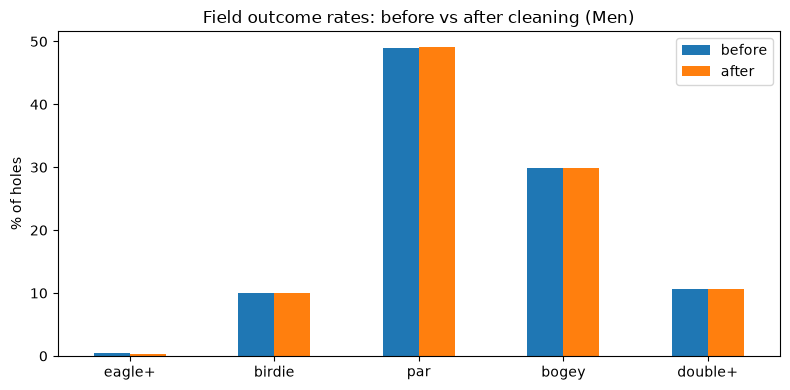

In [10]:
# ---- Validation: prove the cleaning removed artifacts WITHOUT shifting the real signal ----
after_summary = scoring_summary(d3_data)

print("Field outcome rates (%)   [pp = percentage-point change]")
rates = pd.concat([before_summary["outcome_rates"], after_summary["outcome_rates"]], axis=1)
rates.columns = ["before", "after"]
rates["pp_change"] = (rates["after"] - rates["before"]).round(3)
print(rates.to_string(), "\n")

print("Mean to-par by par   (fake par rows gone; std tightens as junk scores leave)")
by_par = pd.concat({"before_mean": before_summary["by_par"]["mean"],
                    "after_mean":  after_summary["by_par"]["mean"],
                    "before_std":  before_summary["by_par"]["std"],
                    "after_std":   after_summary["by_par"]["std"]}, axis=1)
print(by_par.to_string(), "\n")

print("18-hole round to-par   (impossible max collapses; mean/median hold)")
rnd = pd.concat({"before": before_summary["round"], "after": after_summary["round"]}, axis=1)
print(rnd.to_string(), "\n")

# State the round-max result in prose, generated from the actual values (never hardcoded).
_b, _a = before_summary["round"]["max"], after_summary["round"]["max"]
print(f"--> worst 18-hole round: {_b:+.0f} before cleaning  ->  {_a:+.0f} after "
      f"({_b - _a:+.0f} strokes of corruption removed)")
assert _a < _b, "round-level filter did not reduce the maximum round score"

# Visual: real outcomes are unchanged, the "eagle+" artifact is corrected
fig, ax = plt.subplots(figsize=(8, 4))
rates[["before", "after"]].plot(kind="bar", ax=ax)
ax.set_title(f"Field outcome rates: before vs after cleaning ({GENDER})")
ax.set_ylabel("% of holes"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


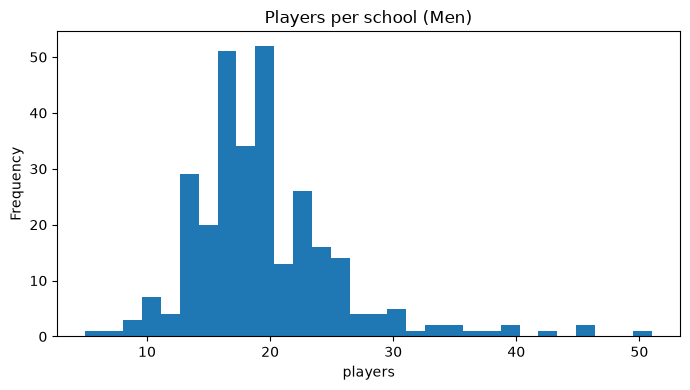

In [11]:
# Scope (gender + tournament level) is already applied by clean_d3 in the CONFIG-driven
# cleaning cell above, so no further filtering happens here.
d3 = d3_data.copy()

# Academic SEASON (Aug-May), not calendar year: college golf plays a fall half and a spring
# half of the SAME season across two calendar years. This data has no Jun/Jul events, so the
# cut is unambiguous: month >= 8 belongs to the season "starting" that calendar year; month <= 5
# belongs to the season that started the PREVIOUS calendar year. season_id is that fall-start
# year as an int (e.g. 2025 for the 2025-26 season); season_label is the readable "2025-26".
_dt = pd.to_datetime(d3["tournament_start_date"], errors="coerce")
d3["season_id"] = _dt.dt.year.where(_dt.dt.month >= 8, _dt.dt.year - 1).astype("Int64")
d3["season_label"] = (d3["season_id"].astype(str) + "-"
                       + (d3["season_id"] + 1).astype("Int64").astype(str).str[-2:])

# players per school
fig, ax = plt.subplots(figsize=(7, 4))
d3.groupby("school_id")["player_id"].nunique().plot(kind="hist", bins=30, ax=ax)
ax.set_title(f"Players per school ({GENDER})"); ax.set_xlabel("players")
plt.tight_layout(); plt.show()


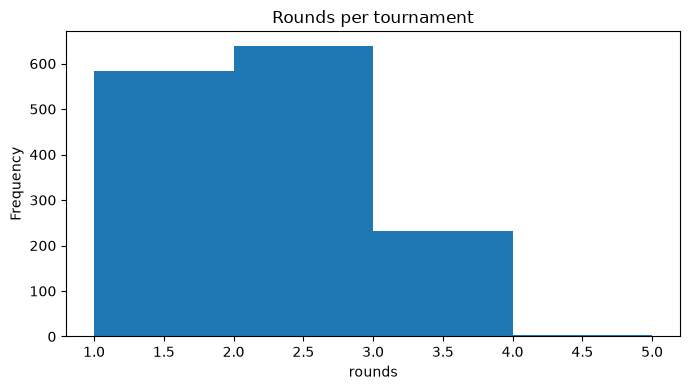

In [12]:
# rounds per tournament
fig, ax = plt.subplots(figsize=(7, 4))
rpt = d3.groupby("tournament_id")["round_number"].nunique()
rpt.plot(kind="hist", bins=range(1, rpt.max() + 2), ax=ax)
ax.set_title("Rounds per tournament"); ax.set_xlabel("rounds")
plt.tight_layout(); plt.show()

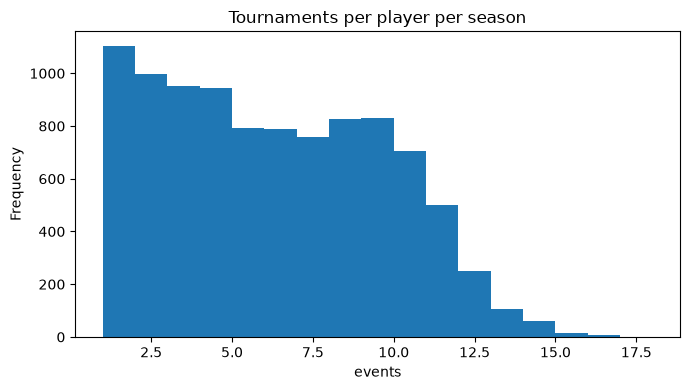

In [9]:
# tournaments per player per season (workload / sample size per player, fair season-over-season)
fig, ax = plt.subplots(figsize=(7, 4))
eppy = d3.groupby(["player_id", "season_id"])["tournament_id"].nunique()
eppy.plot(kind="hist", bins=range(1, eppy.max() + 2), ax=ax)
ax.set_title("Tournaments per player per season"); ax.set_xlabel("events")
plt.tight_layout(); plt.show()

In [13]:
def add_outcomes(df):
    df = df.copy()
    d = df["to_par"]
    df["outcome"] = np.select(
        [d <= -2, d == -1, d == 0, d == 1, d >= 2],
        ["eagle+", "birdie", "par", "bogey", "double+"],
        default="other")
    return df

d3 = add_outcomes(d3)

order = ["eagle+","birdie","par","bogey","double+"]
rates = (d3["outcome"].value_counts(normalize=True)
         .reindex(order) * 100).round(2)
print("Field outcome rates (%):"); print(rates)

Field outcome rates (%):
outcome
eagle+      0.30
birdie     10.00
par        49.15
bogey      29.90
double+    10.66
Name: proportion, dtype: float64


## Hole-level strokes gained, and its carry-over to the next hole

**Idea.** For every hole actually played, compare a player's score to what the *rest of the field*
shot on that same hole under the same conditions (same tournament, same round, same hole number).
That is our "expected" score; beating it is positive strokes gained (SG).

Then we look one hole ahead — *within the same round only* — to ask a simple momentum question:
**does gaining strokes on a hole tell us anything about the next hole?**

Definitions:

- `field_avg` = **leave-one-out** mean `score` over `(tournament_id, round_number, hole_number)` —
  the field on that hole that round, *excluding the player being measured*. A player must not be
  part of the benchmark they are scored against; including themselves drags the benchmark toward
  their own score and shrinks SG toward zero. (We deliberately leave `course_id` out of the key: it
  is fully missing for hundreds of tournaments, and each tournament-round is a single course anyway,
  so keying on it would only drop rows to NaN for no gain.)
- `field_size` = how many players played that hole. Holes with fewer than `MIN_FIELD_SIZE` players
  get `sg = NaN` — with a field of 1 the "field average" is just the player's own score and SG is
  identically 0 by construction.
- `sg = field_avg - score`  (positive = better than the field)
- `sg_next` / `score_next` = the same player's values on the **immediately following hole** in that
  round. We only count it as a valid "next" hole when it is literally `hole_number + 1`, so we never
  wrap 18 -> 1 or bleed from one round into the next.

**A useful identity.** The leave-one-out field average is *exactly* a per-hole rescaling of the
in-sample one:

$$\mathrm{sg}^{\text{LOO}}_i \;=\; \frac{n}{n-1}\,\mathrm{sg}^{\text{in-sample}}_i$$

That makes it cheap to compute, but it is **not** cosmetic: `n` varies a lot from hole to hole, so
the correction reweights holes relative to each other. It is also undefined at `n = 1`, which is
one more reason for the `MIN_FIELD_SIZE` floor. The cell below asserts the identity holds.


In [11]:
# ---- Step 1: LEAVE-ONE-OUT field average per hole  ->  strokes gained on that hole ----
# NB: course_id is NOT in the key. It is NaN for hundreds of whole tournaments, and every
# tournament-round maps to exactly one course anyway, so including it only threw those rows
# out of the groupby (-> NaN field_avg/sg). tournament + round + hole IS the field.


def add_strokes_gained(df):
    """SG on a hole = (mean score of the REST of the field on that hole) - (player's score)."""
    df = df.copy()
    g = df.groupby(HOLE_KEYS)["score"]
    df["field_size"] = g.transform("size")     # how many players make up that field
    field_sum        = g.transform("sum")

    # Leave-one-out: remove this player from the benchmark they are measured against.
    # Only defined where the field clears MIN_FIELD_SIZE (so the denominator is never 0).
    ok = df["field_size"] >= MIN_FIELD_SIZE
    df["field_avg"] = (field_sum - df["score"]) / (df["field_size"] - 1).where(ok)
    df["sg"] = df["field_avg"] - df["score"]
    return df


# ---- Step 2: the SAME player's next hole in the SAME round (lead), no wrap-around ----
def add_next_hole(df):
    """Add sg_next / score_next via a within-round lead, valid only when it's hole n -> n+1."""
    df = df.sort_values(ROUND_KEYS + ["hole_number"]).copy()
    g = df.groupby(ROUND_KEYS, sort=False)
    df["sg_next"]    = g["sg"].shift(-1)          # pandas' lead == shift(-1)
    df["score_next"] = g["score"].shift(-1)
    nxt_hole         = g["hole_number"].shift(-1)
    # only a real "next hole" if it is the immediately following number in the same round;
    # this drops round-to-round wraps AND the 18 -> 1 wrap, plus any gaps from dropped rows.
    valid = nxt_hole == df["hole_number"] + 1
    df.loc[~valid, ["sg_next", "score_next"]] = np.nan
    return df


d3 = add_next_hole(add_strokes_gained(d3))

# ---- sanity checks ----
pair = d3.dropna(subset=["sg", "sg_next"])
print(f"holes with a usable SG          : {d3['sg'].notna().sum():,} of {len(d3):,} "
      f"({d3['sg'].notna().mean()*100:.1f}%)  [rest below MIN_FIELD_SIZE={MIN_FIELD_SIZE}]")
print(f"holes with a valid next hole    : {len(pair):,} ({len(pair)/len(d3)*100:.1f}%)")
print(f"mean SG (should be ~0 by construction): {d3['sg'].mean():+.4f}")
print(f"mean field size per hole        : {d3['field_size'].mean():.0f} players")

# fix #3: no SG may survive from an under-populated hole
assert d3.loc[d3["sg"].notna(), "field_size"].min() >= MIN_FIELD_SIZE, "SG leaked from a small field"

# fix #2: verify the leave-one-out identity  sg_loo == sg_in_sample * n/(n-1)
_chk = d3[d3["sg"].notna()].sample(min(200_000, int(d3["sg"].notna().sum())), random_state=0)
_g = d3.groupby(HOLE_KEYS)["score"]
_in_sample = (_g.transform("mean") - d3["score"]).loc[_chk.index]
_n = _chk["field_size"]
assert np.allclose(_chk["sg"], _in_sample * _n / (_n - 1)), "LOO identity failed"
print(f"LOO identity  sg == sg_in_sample * n/(n-1)  : verified on {len(_chk):,} sampled holes")

d3[["hole_number", "score", "field_size", "field_avg", "sg", "score_next", "sg_next"]].head(8).round(3)


holes with a usable SG          : 1,826,255 of 1,875,855 (97.4%)  [rest below MIN_FIELD_SIZE=10]
holes with a valid next hole    : 1,724,625 (91.9%)
mean SG (should be ~0 by construction): -0.0000
mean field size per hole        : 68 players
LOO identity  sg == sg_in_sample * n/(n-1)  : verified on 200,000 sampled holes


,hole_number,score,field_size,field_avg,sg,score_next,sg_next
18,1,4,7,NaN,NaN,5.0,NaN
19,2,5,7,NaN,NaN,4.0,NaN
20,3,4,7,NaN,NaN,6.0,NaN
21,4,6,7,NaN,NaN,3.0,NaN
22,5,3,7,NaN,NaN,6.0,NaN
23,6,6,7,NaN,NaN,5.0,NaN
24,7,5,7,NaN,NaN,3.0,NaN
25,8,3,7,NaN,NaN,4.0,NaN


In [12]:
# ---- Rudimentary EDA: does SG on a hole carry over to the next hole? ----
pair = d3.dropna(subset=["sg", "sg_next"]).copy()
x, y = pair["sg"].to_numpy(), pair["sg_next"].to_numpy()

r = np.corrcoef(x, y)[0, 1]
slope, intercept, _, p_value, _ = stats.linregress(x, y)
print(f"n pairs          : {len(pair):,}")
print(f"corr(sg, sg_next): {r:+.4f}   (p = {p_value:.2e})")
print(f"OLS slope        : {slope:+.4f}  -> +1 stroke gained now predicts {slope:+.3f} SG next hole")

# Binned view: average next-hole SG for buckets of this-hole SG (the clearest read of the effect)
bins = [-np.inf, -2, -1, -0.5, 0.5, 1, 2, np.inf]
labels = ["<=-2", "-2..-1", "-1..-.5", "~0 (~par vs field)", ".5..1", "1..2", ">=2"]
pair["sg_bin"] = pd.cut(pair["sg"], bins=bins, labels=labels)
binned = pair.groupby("sg_bin", observed=True)["sg_next"].agg(["mean", "count"])
print("\nMean next-hole SG by this-hole SG bucket:")
print(binned.round(4).to_string())

n pairs          : 1,724,625
corr(sg, sg_next): +0.0979   (p = 0.00e+00)
OLS slope        : +0.0982  -> +1 stroke gained now predicts +0.098 SG next hole

Mean next-hole SG by this-hole SG bucket:
                      mean   count
sg_bin                            
<=-2               -0.3343   43469
-2..-1             -0.1457  145008
-1..-.5            -0.0559  251897
~0 (~par vs field)  0.0153  820819
.5..1               0.0712  306093
1..2                0.0962  152990
>=2                 0.1523    4349


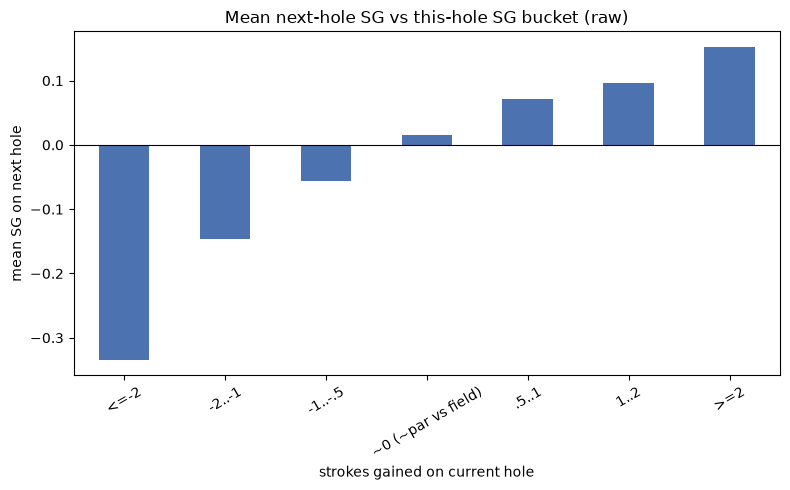

In [13]:
# Graph: mean next-hole SG by this-hole SG bucket (the headline read, raw / uncontrolled)
fig, ax = plt.subplots(figsize=(8, 5))
binned["mean"].plot(kind="bar", ax=ax, color="#4c72b0")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Mean next-hole SG vs this-hole SG bucket (raw)")
ax.set_xlabel("strokes gained on current hole"); ax.set_ylabel("mean SG on next hole")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

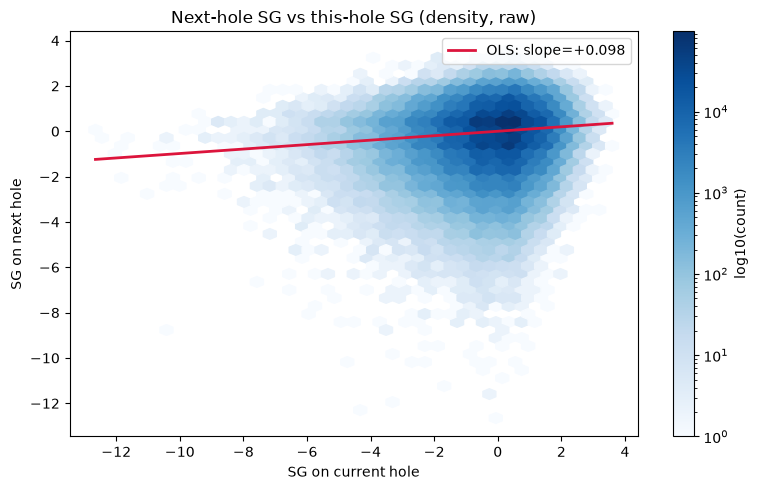

In [14]:
# Graph: density of (this-hole SG, next-hole SG) with the OLS fit
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(x, y, gridsize=40, cmap="Blues", mincnt=1, bins="log")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, intercept + slope * xs, color="crimson", lw=2, label=f"OLS: slope={slope:+.3f}")
ax.set_title("Next-hole SG vs this-hole SG (density, raw)")
ax.set_xlabel("SG on current hole"); ax.set_ylabel("SG on next hole")
ax.legend(loc="upper right")
fig.colorbar(hb, ax=ax, label="log10(count)")
plt.tight_layout(); plt.show()

### Controlling for player quality: subtract each player's *season* average

The raw carry-over could just be **skill** — good players beat the field on both holes, so
consecutive-hole SG looks correlated even with zero momentum. To strip that out we subtract a
player's own baseline SG and re-run the identical correlation on the residual.

**Which baseline?** *Not* the round mean: the two holes we're comparing are themselves part of that
round, so the round average is contaminated by the very values we're studying (it would mechanically
manufacture a negative correlation). Instead we use each player's **season** baseline — `season_id`,
the Aug–May academic season defined above, *not calendar year*. Calendar year would slice one real
competitive season (fall + spring) in half at Jan 1, and lump spring with the following fall — a
different season, ~9 months later — into one bucket.

**Leave-one-out, not a plain mean.** The two holes being compared (`sg`, `sg_next`) are themselves
part of that player-season. Averaging them into their own baseline is the same contamination the
round-mean was rejected for, just milder — for a player-season with few holes it mechanically pulls
the residual (and the correlation) toward zero, independent of any real effect. So `sg_season_mean`
for a given row excludes the current hole *and* the next hole from the mean, and any player-season
with fewer than `MIN_SEASON_HOLES` holes is dropped rather than trusted.

The cell below also caches the raw sums (`_loo_n`, `_loo_s`, `_loo_ss`) that the **volatility**
section reuses, so the mean and the standard deviation are built from an identical exclusion set.


In [15]:
# ---- Control for skill using each player's SEASON (player x season_id) average SG per hole ----
# Baseline = LEAVE-ONE-OUT mean SG over the player-season's OTHER holes, excluding both the
# current hole (sg) and the next hole (sg_next) being tested against it. A plain in-sample mean
# would partly average a player's SG against itself, which mechanically shrinks the correlation
# toward zero -- worse the fewer holes a player-season has.

_g = d3.groupby(SEASON_KEYS)
d3["_sg2"] = d3["sg"] ** 2

season_n  = _g["sg"].transform("count")     # count, not size: sg is NaN below MIN_FIELD_SIZE
season_s  = _g["sg"].transform("sum")
season_ss = _g["_sg2"].transform("sum")

# holes to remove from this row's baseline: the current hole always (when it has an SG),
# and the next hole whenever it exists. Identical exclusion set is reused for the std below.
has_cur, has_nxt = d3["sg"].notna(), d3["sg_next"].notna()
excl_n  = has_cur.astype(int) + has_nxt.astype(int)
excl_s  = d3["sg"].fillna(0) + d3["sg_next"].fillna(0)
excl_ss = d3["sg"].fillna(0) ** 2 + d3["sg_next"].fillna(0) ** 2

# cached for the volatility cell so mean and std share one exclusion set
d3["_loo_n"]  = season_n - excl_n
d3["_loo_s"]  = season_s - excl_s
d3["_loo_ss"] = season_ss - excl_ss

trusted = (season_n >= MIN_SEASON_HOLES) & (d3["_loo_n"] > 0)
d3["sg_season_mean"] = np.where(trusted, d3["_loo_s"] / d3["_loo_n"], np.nan)

# residualize the current AND next hole by the SAME leave-one-out season baseline
d3["sg_r"]      = d3["sg"]      - d3["sg_season_mean"]
d3["sg_next_r"] = d3["sg_next"] - d3["sg_season_mean"]


def corr_slope(df, xcol, ycol):
    s = df.dropna(subset=[xcol, ycol])
    xx, yy = s[xcol].to_numpy(), s[ycol].to_numpy()
    lr = stats.linregress(xx, yy)
    return {"corr": np.corrcoef(xx, yy)[0, 1], "slope": lr.slope, "p": lr.pvalue, "n": len(s)}


results = pd.DataFrame({
    "raw (skill NOT removed)":    corr_slope(d3, "sg",   "sg_next"),
    "minus player-season mean":   corr_slope(d3, "sg_r", "sg_next_r"),
}).T
print(f"Carry-over of SG to the next hole ({GENDER}), before vs after removing season-level skill:")
print("NOTE: the p column is NOT trustworthy as printed -- see the clustering caveat below.\n")
print(results.assign(n=results["n"].astype(int)).round(4).to_string())


Carry-over of SG to the next hole (Men), before vs after removing season-level skill:
NOTE: the p column is NOT trustworthy as printed -- see the clustering caveat below.

                            corr   slope    p        n
raw (skill NOT removed)   0.0979  0.0982  0.0  1724625
minus player-season mean  0.0360  0.0361  0.0  1687899


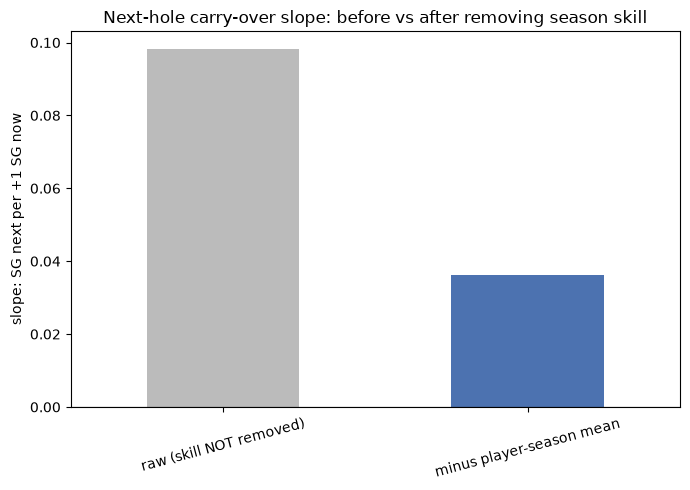

In [16]:
# Graph: carry-over slope, raw vs after removing season skill
fig, ax = plt.subplots(figsize=(7, 5))
results["slope"].plot(kind="bar", ax=ax, color=["#bbbbbb", "#4c72b0"])
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Next-hole carry-over slope: before vs after removing season skill")
ax.set_ylabel("slope: SG next per +1 SG now"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

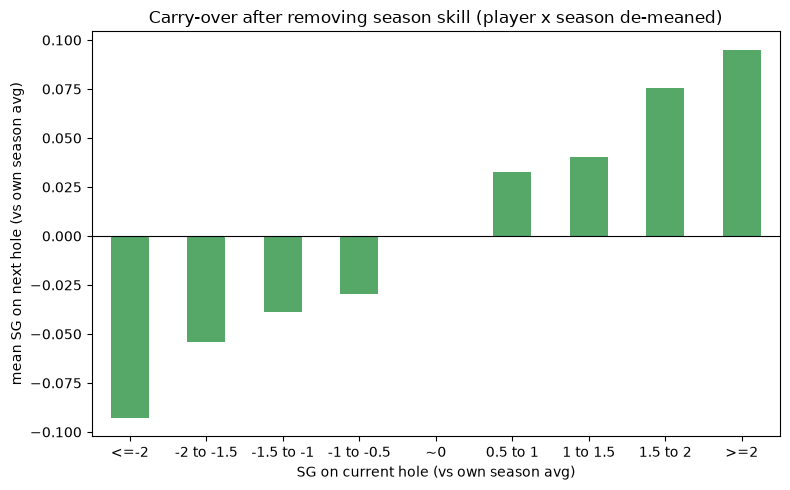

In [17]:
# Graph: season-residual binned means -> the skill-controlled carry-over
bins = [-np.inf, -2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2, np.inf]
labels = ["<=-2", "-2 to -1.5", "-1.5 to -1", "-1 to -0.5", "~0",
          "0.5 to 1", "1 to 1.5", "1.5 to 2", ">=2"]
res = d3.dropna(subset=["sg_r", "sg_next_r"]).copy()
res["sg_bin"] = pd.cut(res["sg_r"], bins=bins, labels=labels)
binned_r = res.groupby("sg_bin", observed=True)["sg_next_r"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
binned_r.plot(kind="bar", ax=ax, color="#55a868")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Carry-over after removing season skill (player x season de-meaned)")
ax.set_xlabel("SG on current hole (vs own season avg)")
ax.set_ylabel("mean SG on next hole (vs own season avg)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### Controlling for volatility too: a z-score carry-over

The season-mean residual (`sg_r`) strips out *how good* a player is, but not *how streaky* they are.
A raw `sg_r` of +1 means something very different for a metronomic player than for a wild one — it's
a huge deviation for the former and just noise for the latter.

So we also give each player-season a **volatility index**: the standard deviation of their hole-level
SG that season (`sg_season_vol`). Dividing the season-mean residual by that std turns SG into a
**z-score** — "how many of *this player's own* standard deviations above/below their normal hole was
this?" We compute it the same way for the current hole and the next hole (same player, same season,
so the same mean/std apply to both), then ask the identical carry-over question on the standardized
scale:

- `sg_z = sg_r / sg_season_vol`, `sg_next_z = sg_next_r / sg_season_vol`
- `diff_z = sg_next_z - sg_z` — how much of a standardized swing "survives" (positive) or reverts
  (negative) into the very next hole, in units of the player's *own* noise.

**The std is leave-one-out too.** This is the same argument as for the mean, and it previously was
*not* applied here: `sg_season_vol` used a plain season-wide standard deviation that included the
very two holes being tested against it. A hole contributing to its own denominator biases the
z-score — inflating the denominator exactly when the hole was unusual, which drags `sg_z` toward
zero precisely on the observations that carry the signal. It now excludes the current hole and the
next hole, using the identical exclusion set as `sg_season_mean`, computed from the cached sums via

$$s^2_{\text{LOO}} \;=\; \frac{\sum x^2 - \left(\sum x\right)^2 / n}{n - 1}$$

Player-seasons with too few holes give an unreliable std, so we still require at least
`MIN_SEASON_HOLES` holes and drop any zero/NaN std to avoid divide-by-zero blowups — the same floor
already applied to `sg_season_mean`, so the mean and the std are now trusted (or not) over an
identical set of player-seasons **and** estimated the same way.


In [18]:
# ---- Volatility index: each player-season's LEAVE-ONE-OUT std of hole-level SG ----
# Reuses the cached _loo_n / _loo_s / _loo_ss from the season-mean cell, so the mean and the
# std exclude exactly the same holes (current + next) over exactly the same player-seasons.

_n, _s, _ss = d3["_loo_n"], d3["_loo_s"], d3["_loo_ss"]

# sample variance from raw sums:  (sum x^2 - (sum x)^2 / n) / (n - 1)
_var = (_ss - _s ** 2 / _n.where(_n > 0)) / (_n - 1).where(_n > 1)
_var = _var.clip(lower=0)                      # kill tiny negatives from floating-point error
d3["sg_season_vol"] = np.sqrt(_var)

season_n = d3.groupby(SEASON_KEYS)["sg"].transform("count")
valid_vol = (
    (season_n >= MIN_SEASON_HOLES)
    & d3["sg_season_vol"].notna()
    & (d3["sg_season_vol"] > 0)
)
print(f"player-season holes meeting the >= {MIN_SEASON_HOLES}-hole volatility threshold: "
      f"{valid_vol.mean()*100:.1f}%")

# sanity: LOO std must be finite/positive, and close to -- but not identical to -- the plain std
_plain = d3.groupby(SEASON_KEYS)["sg"].transform("std")
_cmp = pd.DataFrame({"loo": d3["sg_season_vol"], "plain": _plain}).dropna()
assert np.isfinite(_cmp["loo"]).all() and (_cmp["loo"] > 0).all(), "bad LOO std"
assert not np.allclose(_cmp["loo"], _cmp["plain"]), "LOO std is identical to the plain std"
print(f"LOO vs plain season std: mean abs diff {np.abs(_cmp['loo'] - _cmp['plain']).mean():.5f}, "
      f"max {np.abs(_cmp['loo'] - _cmp['plain']).max():.4f}  (small but non-zero, as expected)")

# z-score current/next hole using the SAME player-season mean & std
d3["sg_z"]      = np.where(valid_vol, d3["sg_r"]      / d3["sg_season_vol"], np.nan)
d3["sg_next_z"] = np.where(valid_vol, d3["sg_next_r"] / d3["sg_season_vol"], np.nan)
d3["diff_z"]    = d3["sg_next_z"] - d3["sg_z"]

zpair = d3.dropna(subset=["sg_z", "sg_next_z"])
print(f"\nn pairs with a valid z-score both holes: {len(zpair):,}")
print(zpair["sg_z"].describe().round(3).to_string())


player-season holes meeting the >= 54-hole volatility threshold: 97.8%
LOO vs plain season std: mean abs diff 0.00378, max 1.9957  (small but non-zero, as expected)

n pairs with a valid z-score both holes: 1,687,899
count    1687899.000
mean          -0.002
std            1.010
min          -13.278
25%           -0.594
50%            0.148
75%            0.623
max            4.699


In [19]:
# ---- Same corr/slope comparison, now with the z-score (skill + volatility removed) added ----
results_z = pd.concat([
    results,
    pd.DataFrame({"z-score (skill + volatility removed)": corr_slope(d3, "sg_z", "sg_next_z")}).T,
])
print("Carry-over of SG to the next hole, raw vs season-residual vs volatility-standardized:\n")
print(results_z.assign(n=results_z["n"].astype(int)).round(4).to_string())

Carry-over of SG to the next hole, raw vs season-residual vs volatility-standardized:

                                        corr   slope    p        n
raw (skill NOT removed)               0.0979  0.0982  0.0  1724625
minus player-season mean              0.0360  0.0361  0.0  1687899
z-score (skill + volatility removed)  0.0327  0.0328  0.0  1687899


### Caveat: the printed p-values understate uncertainty (clustered observations)

`stats.linregress` assumes every row is an independent observation. These rows are not. The
hole-pairs come from ~104K player-rounds with up to 18 holes each, and everything shared within a
round — tee time, wind, pin positions, whether the player was swinging well that day — makes holes
inside a round move together for reasons that have nothing to do with hole-to-hole momentum. The
effective sample is far closer to the number of *rounds* than the number of *holes*.

Measured on this data by resampling whole player-rounds (bootstrap, clustered on
`ROUND_KEYS`):

| quantity | value |
|---|---|
| hole-pairs | ~1.77M |
| independent clusters (player-rounds) | ~104K |
| naive i.i.d. SE of the correlation | `0.000751` |
| round-clustered bootstrap SE | `0.001256` |
| **design effect** | **1.67×** |
| raw carry-over 95% CI (clustered) | **0.0964 – 0.1013** |

Two things follow:

1. **The effect survives.** The clustered interval is comfortably away from zero, so the carry-over
   finding is not an artifact of pseudo-replication.
2. **The printed `p` is still meaningless.** At n ≈ 1.8M, `p` prints as `0.00e+00` for a correlation
   of 0.005 just as readily as for one of 0.5. Read it as "the sample is large", never as "the
   evidence is strong". The number that carries meaning is the **effect size**: r ≈ 0.10 is
   R² ≈ 1%, so this-hole SG explains about one percent of next-hole SG.

Implementing clustered inference throughout (replacing every `linregress` p-value with a clustered
bootstrap CI) is deliberately deferred; this cell records the measured design effect so the
correction factor is not lost in the meantime.


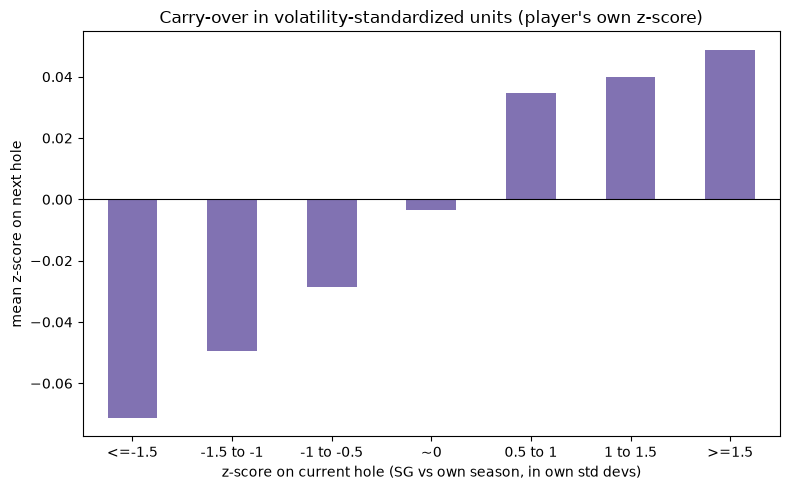

In [20]:
# Graph: binned z-score carry-over -> next-hole z-score by bucket of this-hole z-score
z_bins = [-np.inf, -1.5, -1, -0.5, 0.5, 1, 1.5, np.inf]
z_labels = ["<=-1.5", "-1.5 to -1", "-1 to -0.5", "~0", "0.5 to 1", "1 to 1.5", ">=1.5"]
zres = d3.dropna(subset=["sg_z", "sg_next_z"]).copy()
zres["sg_z_bin"] = pd.cut(zres["sg_z"], bins=z_bins, labels=z_labels)
binned_z = zres.groupby("sg_z_bin", observed=True)["sg_next_z"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
binned_z.plot(kind="bar", ax=ax, color="#8172b2")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Carry-over in volatility-standardized units (player's own z-score)")
ax.set_xlabel("z-score on current hole (SG vs own season, in own std devs)")
ax.set_ylabel("mean z-score on next hole")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

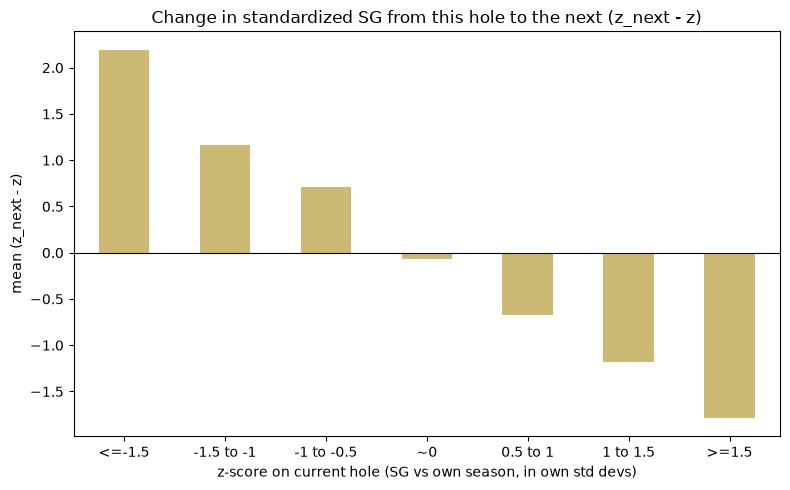

In [21]:
# Graph: diff_z (next-hole z minus current-hole z) by bucket of this-hole z-score
# Negative bars = reversion (next hole gives back some of the standardized swing);
# a bar sitting above -sg_z_bin's own value would mean the swing persists rather than reverts.
binned_diff = zres.groupby("sg_z_bin", observed=True)["diff_z"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
binned_diff.plot(kind="bar", ax=ax, color="#ccb974")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Change in standardized SG from this hole to the next (z_next - z)")
ax.set_xlabel("z-score on current hole (SG vs own season, in own std devs)")
ax.set_ylabel("mean (z_next - z)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## Per-hole strokes-gained matrix

One row per **player-round** (player, tournament, round), one column per hole `h1 … h18`, holding the hole-level `sg` we already built (field mean score on that exact tournament/round/hole minus the player's score). **Positive = beat the field on that hole.** `NaN` means the player didn't play that hole number in that round.

In [22]:
# ---- Wide per-hole SG matrix: (player, tournament, round) x hole, plus round SG ----
sg_matrix = (
    d3.pivot_table(
        index=["player_name", "player_id", "tournament_name", "round_number"],
        columns="hole_number", values="sg", aggfunc="mean",
    )
    .round(3)
)
sg_matrix.columns = [f"h{int(h)}" for h in sg_matrix.columns]   # hole_number -> h1..h18
hole_cols = list(sg_matrix.columns)

# round SG is the additive sum of the hole SGs (skips holes not played)
sg_matrix["round_sg"] = sg_matrix[hole_cols].sum(axis=1).round(3)
sg_matrix["holes_played"] = sg_matrix[hole_cols].notna().sum(axis=1)
sg_matrix = sg_matrix.reset_index()

# order: keys, round_sg, holes_played, then h1..h18
keys = ["player_name", "player_id", "tournament_name", "round_number"]
sg_matrix = sg_matrix[keys + ["round_sg", "holes_played"] + hole_cols]

print(f"{len(sg_matrix):,} player-rounds x {len(hole_cols)} holes")
sg_matrix.head(10)

### Validation: does round SG equal the sum of the hole SGs?

By construction `round_sg = h1 + … + h18`. We cross-check it against an **independent** round SG
built the other way around — from each player's *round total* rather than from their holes.

Both sides must use the **same leave-one-out convention**, or they cannot agree: the hole-level `sg`
excludes the player from each hole's field, so the round-level benchmark has to exclude them from the
field of round totals too. The independent estimate is therefore

$$\text{round\_sg}^{\,\text{indep}} \;=\; \frac{\sum_{j \neq i} \text{total}_j}{N-1} \;-\; \text{total}_i$$

over the players who completed 18 holes in that tournament-round.

The two agree exactly for the overwhelming majority of complete rounds. The small residual is **not**
an error: the per-hole field (who played hole *h*) is not identical to the set of 18-hole finishers
used for the round-total average, so partial rounds and withdrawals shift a few hole means slightly.
The additive `round_sg` in the pivot is the self-consistent metric.


In [23]:
# ---- Independent round SG (LEAVE-ONE-OUT field mean round total - player round total) ----
# Must mirror the hole-level LOO convention, else the two definitions cannot agree by construction.
rt = d3.groupby(ROUND_KEYS).agg(rtot=("score", "sum"), holes=("score", "size")).reset_index()
rt18 = rt[rt["holes"] == 18].copy()

_fg = rt18.groupby(["tournament_id", "round_number"])["rtot"]
_N, _S = _fg.transform("size"), _fg.transform("sum")
# leave-one-out mean of the OTHER players' round totals (undefined for a field of one)
rt18["round_sg_indep"] = (_S - rt18["rtot"]) / (_N - 1).where(_N > 1) - rt18["rtot"]

# additive round SG from the hole SGs. count (not size) -> require all 18 holes to HAVE an SG,
# since holes below MIN_FIELD_SIZE are deliberately NaN.
add = d3.groupby(ROUND_KEYS).agg(round_sg_add=("sg", "sum"), holes=("sg", "count")).reset_index()
add = add[add["holes"] == 18]

chk = rt18.merge(add, on=ROUND_KEYS).dropna(subset=["round_sg_indep", "round_sg_add"])
chk["diff"] = chk["round_sg_indep"] - chk["round_sg_add"]   # both raw floats
exact = (chk["diff"].abs() < 1e-6).mean()
print(f"18-hole player-rounds checked : {len(chk):,}")
print(f"exactly equal (|diff|<1e-6)   : {exact*100:.2f}%")
print(f"within 0.01 strokes           : {(chk['diff'].abs() < 0.01).mean()*100:.2f}%")
print(f"max |diff|                    : {chk['diff'].abs().max():.3f} strokes")
print(f"mean |diff|                   : {chk['diff'].abs().mean():.4f} strokes")
assert exact > 0.99, "round SG and sum-of-hole SG diverge on too many rounds"


18-hole player-rounds checked : 101,274
exactly equal (|diff|<1e-6)   : 99.67%
within 0.01 strokes           : 99.68%
max |diff|                    : 0.744 strokes
mean |diff|                   : 0.0008 strokes


### Just a Couple of Notes for my meeting with Ron Yurko

- Conference and how that was
- Jobs for the upcoming year (focusing on sports teams), teamworks connection, data labeling seems like a waste of time, producing a "finished product" for this golf project. 
    - Working with BTA Sports, selling my sports betting startup. 
    - Putting a good push.
- wrap up, feedback, things like that. 
- Future and what that looks like
- Thank you card. 


Conversations started early is really good and is a very good place to be. 
Think about our portfolio and consider substack for sports and just random thoughts. 
Rob Kass --> really intersting professor in nuerosccience as. a vessel for statistics. 
You have to apply online and then you need to do some networking. Prof Yurko can help me connect to them.

Networkign is coming more important with AI---> Concerns with people generating things in technical assessments. 

Full R@D for the Browns. 

Send message to Sports Analytics Club

Selective inference

The sports gene.



Great example of a good paper: https://arxiv.org/pdf/2305.10262
